# Regresjon - Sigurd

Her undersøker vi sammenhengen mellom restaurantvudering, pris, antall stemmer og tjenester ved hjelp av lineær regresjon 

## 1. Lese inn treningsdata

Vi bruker gruppens felles treningsdata til å tilpasse regresjonsmodellen. Testdataene brukes senere til å evaluere hvor godt modellen predikerer vurderingen til restauranter den ikke er trent på. 

In [1]:
import pandas as pd

train = pd.read_csv("../data/train.csv")

train.head()

,rating,high_rating,cost,log_cost,votes,log_votes,price_range,table_booking,online_delivery,city
0,3.8,1,1200,7.090077,46,3.828641,3,0,0,Noida
1,3.7,1,1800,7.495542,234,5.455321,3,1,0,New Delhi
2,3.6,1,900,6.802395,426,6.054439,2,1,1,Gurgaon
3,4.3,1,1200,7.090077,31,3.433987,3,1,1,New Delhi
4,3.0,0,450,6.109248,14,2.639057,1,0,0,Noida


## 2. Kontrollere treningsdata

Vi undersøker antall observasjoner, datatypene og om noen verdier mangler før vi tilpasser regresjonsmodellen.

In [2]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5203 entries, 0 to 5202
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   rating           5203 non-null   float64
 1   high_rating      5203 non-null   int64  
 2   cost             5203 non-null   int64  
 3   log_cost         5203 non-null   float64
 4   votes            5203 non-null   int64  
 5   log_votes        5203 non-null   float64
 6   price_range      5203 non-null   int64  
 7   table_booking    5203 non-null   int64  
 8   online_delivery  5203 non-null   int64  
 9   city             5203 non-null   object 
dtypes: float64(3), int64(6), object(1)
memory usage: 406.6+ KB


Treningssettet inneholder 5203 restauranter og 10 variabler. Ingen av kolonnene har manglende verdier. 

## 3. Tilpasse en multippel lineær regresjonsmodell 

Vi bruker rating som responsvariabel og log_cost, log_votes, table_booking, online_delivery og city som forklaringsvariabler

Modellen brukes til å undersøke sammenhengen mellom pris og vurdering når vi samtidig tar hensyn til antall stemmer, tjenester og by. 

In [3]:
import statsmodels.formula.api as smf

formel = "rating ~ log_cost + log_votes + table_booking + online_delivery + city" 

modell = smf.ols(formula= formel, data= train).fit()

print(modell.summary())

                            OLS Regression Results                            
Dep. Variable:                 rating   R-squared:                       0.435
Model:                            OLS   Adj. R-squared:                  0.434
Method:                 Least Squares   F-statistic:                     570.3
Date:                Thu, 05 Nov 2026   Prob (F-statistic):               0.00
Time:                        12:15:12   Log-Likelihood:                -2315.8
No. Observations:                5203   AIC:                             4648.
Df Residuals:                    5195   BIC:                             4700.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept             2.5175      0.05

## 4. Foreløpig tolkning

Modellen forklarer 43,5% av variasjonene i vurderingene i treningssettet (R^2 = 0,435, justert R^2 = 0,434). 

Koeffisienten for log_cost er 0,0111, med p-verdi 0,262 og et 95% konfidensintervall på omtrent [-0.088, 0.030]. Vi finner derfor ikke statistisk støtte for H1 ved et signifikansnivå på 5%, når vi kontrollerer for de øvrige variablene. 

Tolkningen er foreløpig, og vi undersøker modellens forutsetninger med residualplott før vi trekker endelige konklusjoner. 

## 5. Undersøke residualene

Vi lager et Tukey-Anscombe-plott med predikerte vurderinger på x-aksen og residualer på y-aksen. 

Vi ser etter om residualene ligger rundt null uten tydelig kurvemønster, og om spredningen er omtrent lik langs y-aksen. 

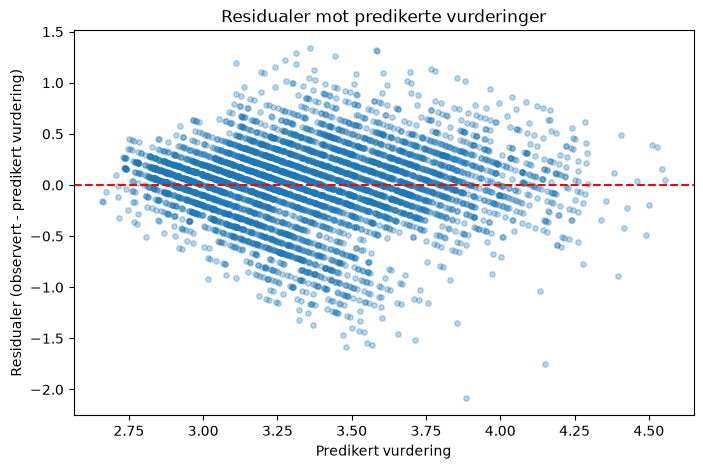

In [4]:
import matplotlib.pyplot as plt

predikert = modell.fittedvalues
residualer = modell.resid

plt.figure(figsize=(8, 5))

plt.scatter(predikert, residualer, alpha= 0.3, s= 15)
plt.axhline(y= 0, color="red", linestyle= "--")

plt.xlabel("Predikert vurdering")
plt.ylabel("Residualer (observert - predikert vurdering)")
plt.title("Residualer mot predikerte vurderinger")

plt.show()

Residualplottet viser tydelige skrå striper nedover. Disse oppstår fordi vurderingene er avrundet til en desimal. Restauranter med samme observerte vurdering følger linjen residual = vurdering - predikert verdi. 

Residualene ligger på begge sider av null, men spredningen ser ut til å variere med predikert vurdering. Antakelsen om konstant varians er derfor usikker. Enkelte restauranter har også store negative residualer, som betyr at modellen overvurderer vurderingene deres. 

## 6. QQ-plott av residualene

Vi sammenligner residualenes fordeling med en normalfordeling. Dersom residualene er omtrent normalfordelte, forventer vi at punktene ligger nær referanselinjen. 

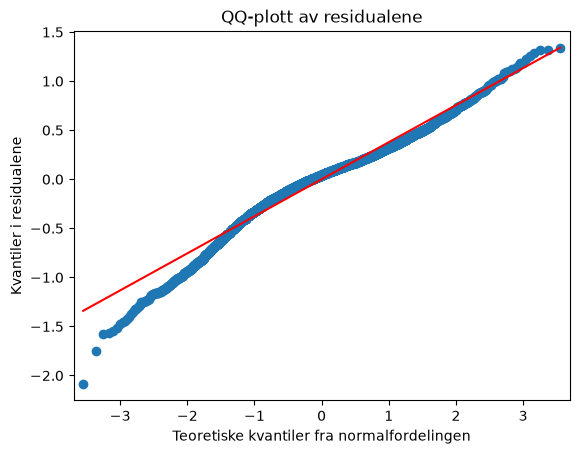

In [5]:
import statsmodels.api as sm

sm.qqplot(residualer, line= "s")

plt.title("QQ-plott av residualene")
plt.xlabel("Teoretiske kvantiler fra normalfordelingen")
plt.ylabel("Kvantiler i residualene")

plt.show()

QQ-plottet viser at residualene følger referanselinjen relativt godt rundt midten, men med tydelige avvik i venstre hale. Dette tyder på flere eller mer ekstreme negative residualer enn ved en normalfordeling. 

Normalitetsantakelsen er derfor ikke fullt oppfylt. Sammen med den varierende spredningen i residualplottet gir dette grunn til forsiktig tolkning av modellens p-verdier og konfidensintervaller. 

## 7. Evaluere modellen på testdata

Vi bruker den ferdige tilpassede modellen til å predikere vurderingene i gruppen felles testsett. 

Predikasjonsfeilen måles med RMSE, som er kvadratroten av gjennomsnittlig kvadrert feil. RMSE måles i vurderingspoeng, og er bedre jo lavere verdi den får. 

Som sammenligningsgrunnlag bruker vi en enkel modell som alltid predikerer gjennomsnittlig vurdering fra treningssettet. 

In [6]:
test = pd.read_csv("../data/test.csv")

predikert_test = modell.predict(test)

rmse = ((test["rating"] - predikert_test) ** 2).mean() ** 0.5

gjennomsnitt_train = train["rating"].mean()
rmse_baseline = ((test["rating"] - gjennomsnitt_train) ** 2).mean() ** 0.5

print(f"RMSE for regresjonsmodellen: {rmse:.3f}")
print(f"RMSE for gjennomsnittsmodellen: {rmse_baseline:.3f}")

RMSE for regresjonsmodellen: 0.392
RMSE for gjennomsnittsmodellen: 0.513


Regresjonsmodellen får RMSE = 0.392 på testsettet, mens gjennomsnittsmodellen får RMSE = 0.513. Dette tilsvarer omtrent 24% lavere RMSE.

Modellen gir dermed en bedre prediksjon på testsettet enn å bruke gjennomsnittlig vurdering fra treningssettet for alle restauranter. Residualanalysen viser samtidig begrensninger ved modellens antakelser. 

## 8. Resultattabell

Tabellen viser estimerte koeffisienter, standardfeil, p-verdier og 95% konfidensintervaller for regresjonsmodellen. 

In [7]:
konfidensintervall = modell.conf_int()

resultattabell = pd.DataFrame({
    "Koeffisient": modell.params,
    "Standardfeil": modell.bse,
    "p-verdi": modell.pvalues,
    "KI nedre": konfidensintervall[0],
    "KI øvre": konfidensintervall[1]
})

resultattabell

,Koeffisient,Standardfeil,p-verdi,KI nedre,KI øvre
Intercept,2.517506,0.058801,0.000000e+00,2.402230,2.632781
city[T.New Delhi],-0.020182,0.015707,1.989017e-01,-0.050975,0.010612
city[T.Noida],-0.120312,0.021625,2.775178e-08,-0.162706,-0.077918
city[T.Other],0.208881,0.021253,1.335449e-22,0.167217,0.250546
log_cost,0.011056,0.009846,2.615695e-01,-0.008247,0.030358
log_votes,0.197892,0.004211,0.000000e+00,0.189635,0.206148
table_booking,0.009262,0.017859,6.040637e-01,-0.025749,0.044272
online_delivery,-0.071191,0.011573,8.246228e-10,-0.093879,-0.048504


## 9. Oppsummering av regresjonsanalysen

Vi tilpasset en mulitppel lineær regresjonsmodell med vurdering som respons og log-transformert pris, log-transformert antall stemmer, bordbestilling, nettlevering og by som forklaringsvariabler. 

Modellen forklarer 43.5% av variasjonen i vurderingene i treningssettet. På testsettet får modellen RMSE = 0.392, sammenlignet med 0.513 for gjennomsnittsmodellen, noe som tilsvarer omtrent 24% levere RMSE. 

Selv om priskoeffisienten er positiv, er den ikke statistisk signifikant (koeffisient = 0.0111, p = 0.262). Vi finner dermed ikke statistisk støtte for H1 ved et signifikansnivå på 5% når vi kontroller for de øvrige variablene.

Det viser seg at antall stemmer har en positiv sammenheng med vurderingen. Restauranter med nettlevering har lavere estimert vurdering enn restauranter uten nettlevering, når de øvrige forklaringsvariablene holdes faste. Analysen viser sammenhenger, men ikke årsaksforhold. 

Residualplottet tyder på varierende sprdening og QQ-plottet viser avvik fra normalfordelingen, spesielt i den venstre "halen". Modellens p-verdier og konfidensintervaller må tolkes med forsiktighet. 